# Batch processing of GRS L2A images with GRSl2bgen

Batch notebook of the [GRSl2bgen documentation](https://grsl2bgen.readthedocs.io/en/latest/tutorials/grsl2bgen_batch_processing.html); the same batch from the command line is given in its last section.

This notebook processes full Sentinel-2 tiles of GRS Level-2A products (Zarr
pyramids or NetCDF files) into GRSl2bgen Level-2B water quality products, for one or
several tiles and a date range:

1. **Configuration**: input/output folders, tiles, date range, GRS version, output format.
2. **List the L2A products** found on disk: incomplete products are left out and, when
   a date was processed by several GRS versions, only one is kept.
3. **Output naming**: one folder per L2B product, `<tile>/YYYY/MM/DD/<name>/`, holding
   the product, its log and its STAC Item.
4. **Run the batch**: products already processed (STAC Item present) are skipped, a failing product
   is logged and does not stop the batch, and a summary table is saved.
5. **Quick look** at one L2B product.

The listing, naming, completeness checks, processing and profiling functions are those of
{mod}`grstbx.batch`, gathered in {class}`~grstbx.batch.Batch` (here without the L2A step of
{doc}`grs_l1c_l2a_l2b_batch`); each product also gets a profiling file,
`<odir>/profiles/<tile>/<L2A name>_profile.json`.

A full tile (5490 x 5490 pixels at 20 m) takes about 70 s and 6 GB of RAM. For very
long batches, the command line is more robust than a notebook: each product
runs in its own Python process, so memory is fully released between products (see the
last section).

```{note}
The outputs shown here come from a short run: tile 31TFJ only (54 L2A products
found) and the dates 2021-02-11 to 2021-02-13, i.e. two full tiles. The notebook is not
re-executed when the documentation is built (the data are not available there); the
INFO log of the processing chain is left out (it is in the log file of each product).
```

In [1]:
import os
import logging
import warnings
import contextlib

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

import GRSl2bgen
from grstbx import batch

opj = os.path.join

# INFO messages of the processing chain; set to logging.WARNING for a quieter batch
logging.getLogger().setLevel(logging.INFO)
# GRS L2A files are stored with chunks that do not match the processing chunks:
# harmless for the results, so the performance hint is silenced
warnings.filterwarnings('ignore', message='The specified chunks separate the stored chunks')

print(f'GRSl2bgen: {GRSl2bgen.__version__}')

GRSl2bgen: 1.1.0dev0


## 1. Configuration

The L2A products are expected in a `<rootdir>/<tile>/YYYY/MM/DD/<product>/` tree, where
`<product>/` is a GRS output directory holding either

- the Zarr pyramid `<product>.zarr` (GRS V3), or
- the NetCDF files `<product>.nc` (main product) and `<product>_anc.nc` (ancillary
  data), e.g. `/data/satellite/Sentinel-2/L2A/30TWR/2020/04/11/S2B_MSIL2A_20200411T110619_N0500_R137_T30TWR_20230509T002033_V2.2.1/`,

and the GRS `log_file.log`. The format is detected product by product, so both can be
mixed under the same `rootdir`; NetCDF files placed directly in the `DD/` folders
(`<product>.nc`) are accepted too. The L2B products are written to the same tree under
`<odir>`, one folder per product (see section 3).

| Parameter | Description |
|---|---|
| `rootdir`, `odir` | root folders of the L2A inputs and of the L2B outputs |
| `tiles` | list of tiles (e.g. `['31TFJ']`), or `None` for all the tiles found in `rootdir` |
| `pattern` | glob pattern of the L2A product names |
| `start_date`, `end_date` | date range to process (inclusive) |
| `version` | GRS version to process (e.g. `'V3.1.0'`), or `None` to keep, for each date, the highest version found |
| `level` | pyramid level read from a Zarr L2A: `0` is the full resolution (20 m, 5490 x 5490 px), level `k` is `2**k` coarser; NetCDF products are always read at full resolution |
| `out_ext` | `'.nc'` (NetCDF) or `'.zarr'` (Zarr store) |
| `pyramid` | for `.zarr`: write a multiscale (pyramid) store for cloud visualisation |
| `overwrite` | reprocess products already processed |
| `stac` | write the STAC Item of each product, last; a product is then complete when its Item exists |
| `n_workers` | `None`: dask threaded scheduler; an integer: one local dask cluster with this many worker processes, shared by the whole batch |
| `persist_input` | keep each masked L2A raster in memory (faster, needs more RAM: several GB for a full tile) |

In [2]:
rootdir = '/data/satellite/Sentinel-2/L2A_zarr'   # GRS NetCDF products: e.g. '/data/satellite/Sentinel-2/L2A'
odir = '/data/satellite/Sentinel-2/L2B'

tiles = ['31TFJ']      # None: all the tiles of rootdir; or e.g. ['31TFJ', '31TEJ']
pattern = '*L2A*'
start_date, end_date = '2021-02-11', '2021-02-13'   # e.g. '2021-01-01', '2025-12-31'
version = 'V3.1.0'     # None: highest GRS version of each date
level = 0              # 0: full resolution (Zarr only)

out_ext = '.nc'        # '.nc' or '.zarr'
pyramid = False        # only for '.zarr'
overwrite = False
stac = True

n_workers = None       # e.g. 4
persist_input = False

## 2. List the L2A products

The product names follow the Sentinel-2 convention, followed by the GRS version:

`<satellite>_<level>_<sensing time>_<baseline>_<orbit>_<tile>_<processing time>_<version>`

e.g. `S2A_MSIL2AGRS_20210820T104021_N0500_R008_T31TFJ_20230122T133008_V3.1.0` (Zarr) or
`S2B_MSIL2A_20200411T110619_N0500_R137_T30TWR_20230509T002033_V2.2.1` (NetCDF). The
products are indexed by sensing time, so that a date range can be selected with `.loc`,
and their format (`zarr` or `nc`) is given in the `format` column.

{func}`~grstbx.batch.list_l2a_products` lists them, and its column `complete`
({func}`~grstbx.batch.l2a_complete`) is true when the product is complete:

- Zarr: its pyramid holds the root metadata and every level listed in it, each with
  the `Rrs` and `mask` arrays (a GRS run that failed while writing the Zarr store
  leaves the level groups without them);
- NetCDF: its main file (and, for a GRS folder, its `_anc.nc` ancillary file) can be
  opened and holds the `Rrs` and `mask` variables.

Products still being written, or left over by a failed GRS run, are reported and
skipped. {func}`~grstbx.batch.select_versions` keeps one GRS version per Level-1 product.

In [3]:
products = batch.list_l2a_products(rootdir, tiles, pattern)
print(f'{len(products)} L2A products found in {rootdir}')
products.groupby(['tile', 'version']).size().rename('products').to_frame().T

54 L2A products found in /data/satellite/Sentinel-2/L2A_zarr


tile,31TFJ
version,V3.1.0
products,54


In [4]:
incomplete = products[~products['complete']]
if len(incomplete):
    print(f'{len(incomplete)} incomplete products skipped:')
    print('\n'.join(incomplete['path']))

# one GRS version per L1C product: the requested version, or the highest one
products = batch.select_versions(products[products['complete']], version)

# same sensing time, different ESA processing times: distinct L1C products, both processed
twins = products[products.reset_index().duplicated(['tile', 'time'], keep=False).values]
if len(twins):
    print(f'{len(twins)} products share their tile and sensing time with another one '
          '(different L1C processing times), all are processed:')
    print('\n'.join(twins['path'].map(os.path.basename)))

selection = products.loc[start_date:end_date]
print(f'{len(selection)} products between {start_date} and {end_date}')
selection.groupby(['tile', selection.index.year]).size().rename('products').unstack(fill_value=0)

2 products between 2021-02-11 and 2021-02-13


time,2021
tile,
31TFJ,2


## 3. Output naming

Each L2B product is named as by the `GRSl2bgen` command line
({func}`~grstbx.batch.l2b_name`, as `GRSl2bgen.run.default_output_name`): the name of its L2A product, with the level tag
`L2AGRS` or `L2A` (any case) replaced by `L2B`, e.g.
`S2A_MSIL2B_20210820T104021_N0500_R008_T31TFJ_20230122T133008_V3.1.0` (Zarr input) or
`S2B_MSIL2B_20200411T110619_N0500_R137_T30TWR_20230509T002033_V2.2.1` (NetCDF input). As with
`GRSl2bgen --product_dir --stac`, each product gets its own folder, ready to be copied
or uploaded (e.g. to an S3 bucket) as a whole:

```
<odir>/<tile>/YYYY/MM/DD/<name>/
    <name>.nc       (or .zarr/)   L2B product
    <name>.log                    log of the run
    <name>.json                   STAC Item, written last
```

{meth}`Batch.plan_l2a <grstbx.batch.Batch.plan_l2a>` adds these names to the table of the L2A
products, with `l2b_done` and `run_l2b`. A product is **done** when its STAC Item exists (its output, if `stac=False`): the
product is written under a temporary name and renamed when complete, and the Item is
written after the product and its log.

In [5]:
run = batch.Batch(l2b_dir=odir, l2b_ext=out_ext, pyramid=pyramid, stac=stac, persist_input=persist_input,
                  level=level, overwrite_l2b=overwrite)
selection = run.plan_l2a(selection)
print(run.describe(selection))
selection[['tile', 'name', 'l2b', 'l2b_done', 'run_l2b']].head()

L2A: 2 complete, 0 incomplete
L2B: 0 done, 2 to compute


,tile,name,l2b,l2b_done,run_l2b
time,,,,,
2021-02-11 10:41:51,31TFJ,S2A_MSIL2AGRS_20210211T104151_N0500_R008_T31TF...,/data/satellite/Sentinel-2/L2B/31TFJ/2021/02/1...,False,True
2021-02-13 10:30:39,31TFJ,S2B_MSIL2AGRS_20210213T103039_N0500_R108_T31TF...,/data/satellite/Sentinel-2/L2B/31TFJ/2021/02/1...,False,True


## 4. Run the batch

{meth}`Batch.run <grstbx.batch.Batch.run>` processes the products one after the other. For each product:

- it is **skipped** if it is done (unless `overwrite=True`), so the batch can be
  interrupted and restarted at any time;
- {func}`~grstbx.batch.run_grsl2bgen`: `Process.run` executes the processing chain (on pyramid level `level` for a Zarr
  input, at full resolution for a NetCDF one), writes the
  output and closes the input files; the log of the run is written to `<name>.log` by
  `GRSl2bgen.logger.RunLogger` (format of the GRS processor, with the peak memory and
  CPU and run times of the product at the end; the peak memory is that of the
  notebook kernel), and the STAC Item is written last;
- if the processing **fails**, the traceback is written to the log, the output (if any)
  is removed so that the product is retried at the next run, and the batch goes on;
- the **profile** of the product (wall time, CPU time and peak memory, memory curve, see
  {class}`~grstbx.batch.Profiler`) is written, whatever the outcome.

With `n_workers` set, a single local dask cluster is started for the whole batch
(instead of one per product) and closed at the end. The INFO log of each product is
long for a batch: set the logging level to `logging.WARNING` in the first cell to keep
only the progress lines.

In [6]:
if n_workers:
    from dask.distributed import Client
    # the client owns the cluster: both are closed at the end of the with block
    scheduler = Client(n_workers=n_workers, threads_per_worker=1)
    print(f'dask dashboard: {scheduler.dashboard_link}')
else:
    scheduler = contextlib.nullcontext()

with scheduler:
    summary = run.run(selection)
summary['status'].value_counts()

[1/2] done       S2A_MSIL2AGRS_20210211T104151_N0500_R008_T31TFJ_20230608T124831_V3.1.0 (79 s)
[2/2] done       S2B_MSIL2AGRS_20210213T103039_N0500_R108_T31TFJ_20230609T061428_V3.1.0 (67 s)


status
done    2
Name: count, dtype: int64

The summary is saved as a CSV file in `odir`. Failed products can be inspected below and
reprocessed by running the batch again.

In [7]:
summary_file = run.save_summary(summary, prefix='l2bgen_batch')
print(f'summary saved to {summary_file}')
processed = summary[summary.status == 'done']
if len(processed):
    print(f'mean processing time: {processed.duration_s.mean():.1f} s per product')

summary[summary.status == 'L2B failed'][['tile', 'error', 'name']]

summary saved to /data/satellite/Sentinel-2/L2B/l2bgen_batch_20261020T194711.csv
mean processing time: 73.2 s per product


,tile,error,name
date,,,


## 5. Quick look at one L2B product

The last processed product of the selection is displayed. A full tile is large for a
figure, so one pixel out of `step` is shown. A pyramid Zarr store holds one group per
resolution level: a coarse level is read directly instead.

In [8]:
done = selection[selection['l2b'].map(lambda p: batch.l2b_complete(p, stac))]
l2b_file = done['l2b'].iloc[-1]
step = 4                            # 1 pixel out of `step` in x and y (80 m for a 20 m tile)
if l2b_file.endswith('.zarr') and pyramid:
    l2b = xr.open_zarr(l2b_file, group='2', decode_coords='all')    # 2**2 coarser
    step = 1
elif l2b_file.endswith('.zarr'):
    l2b = xr.open_zarr(l2b_file, decode_coords='all')
else:
    l2b = xr.open_dataset(l2b_file, decode_coords='all')
l2b = l2b.isel(x=slice(None, None, step), y=slice(None, None, step))
l2b

<xarray.Dataset> Size: 394MB
Dimensions:                    (Nclasses: 3, y: 1373, x: 1373)
Coordinates:
  * Nclasses                   (Nclasses) int64 24B 0 1 2
  * y                          (y) float64 11kB 4.9e+06 4.9e+06 ... 4.79e+06
  * x                          (x) float64 11kB 6e+05 6.001e+05 ... 7.098e+05
    band                       int64 8B ...
    spatial_ref                int32 4B ...
    time                       datetime64[ns] 8B ...
    central_wavelength         float32 4B ...
    wl                         int64 8B ...
Data variables: (12/24)
    owt_dist_Spyrakos2018      (Nclasses, y, x) float64 45MB ...
    owt_index_Spyrakos2018     (Nclasses, y, x) float32 23MB ...
    owt_dist_Bi2024            (y, x) float64 15MB ...
    owt_index_Bi2024           (y, x) float32 8MB ...
    owt_dist_Ta2025            (y, x) float64 15MB ...
    owt_index_Ta2025           (y, x) float32 8MB ...
    ...                         ...
    adg443_QAAv6Chl            (y, x) float64 15MB ...
    Kd_par                     (y, x) float64 15MB ...
    Zsd_Lee15                  (y, x) float64 15MB ...
    flags                      (y, x) uint32 8MB ...
    flags_l2b                  (y, x) uint32 8MB ...
    mask                       (y, x) uint8 2MB ...
Attributes: (12/77)
    long_name:                           CA BLUE GREEN RED VRE_1 VRE_2 VRE_3 ...
    constellation:                       Sentinel-2
    constellation_id:                    S2
    product_path:                        /data/satellite/Sentinel-2/L1C/31TFJ...
    product_name:                        S2B_MSIL1C_20210213T103039_N0500_R10...
    instrument:                          MSI
    ...                                  ...
    hcld_threshold:                      0.003
    dirdata:                             /data/grs/grsdata
    abs_gas_file:                        /home/harmel/Dropbox/Dropbox/work/gi...
    water_vapor_transmittance_file:      /home/harmel/Dropbox/Dropbox/work/gi...
    GRSdriver_version:                   2.0.4
    metadata_profile:                    datacube

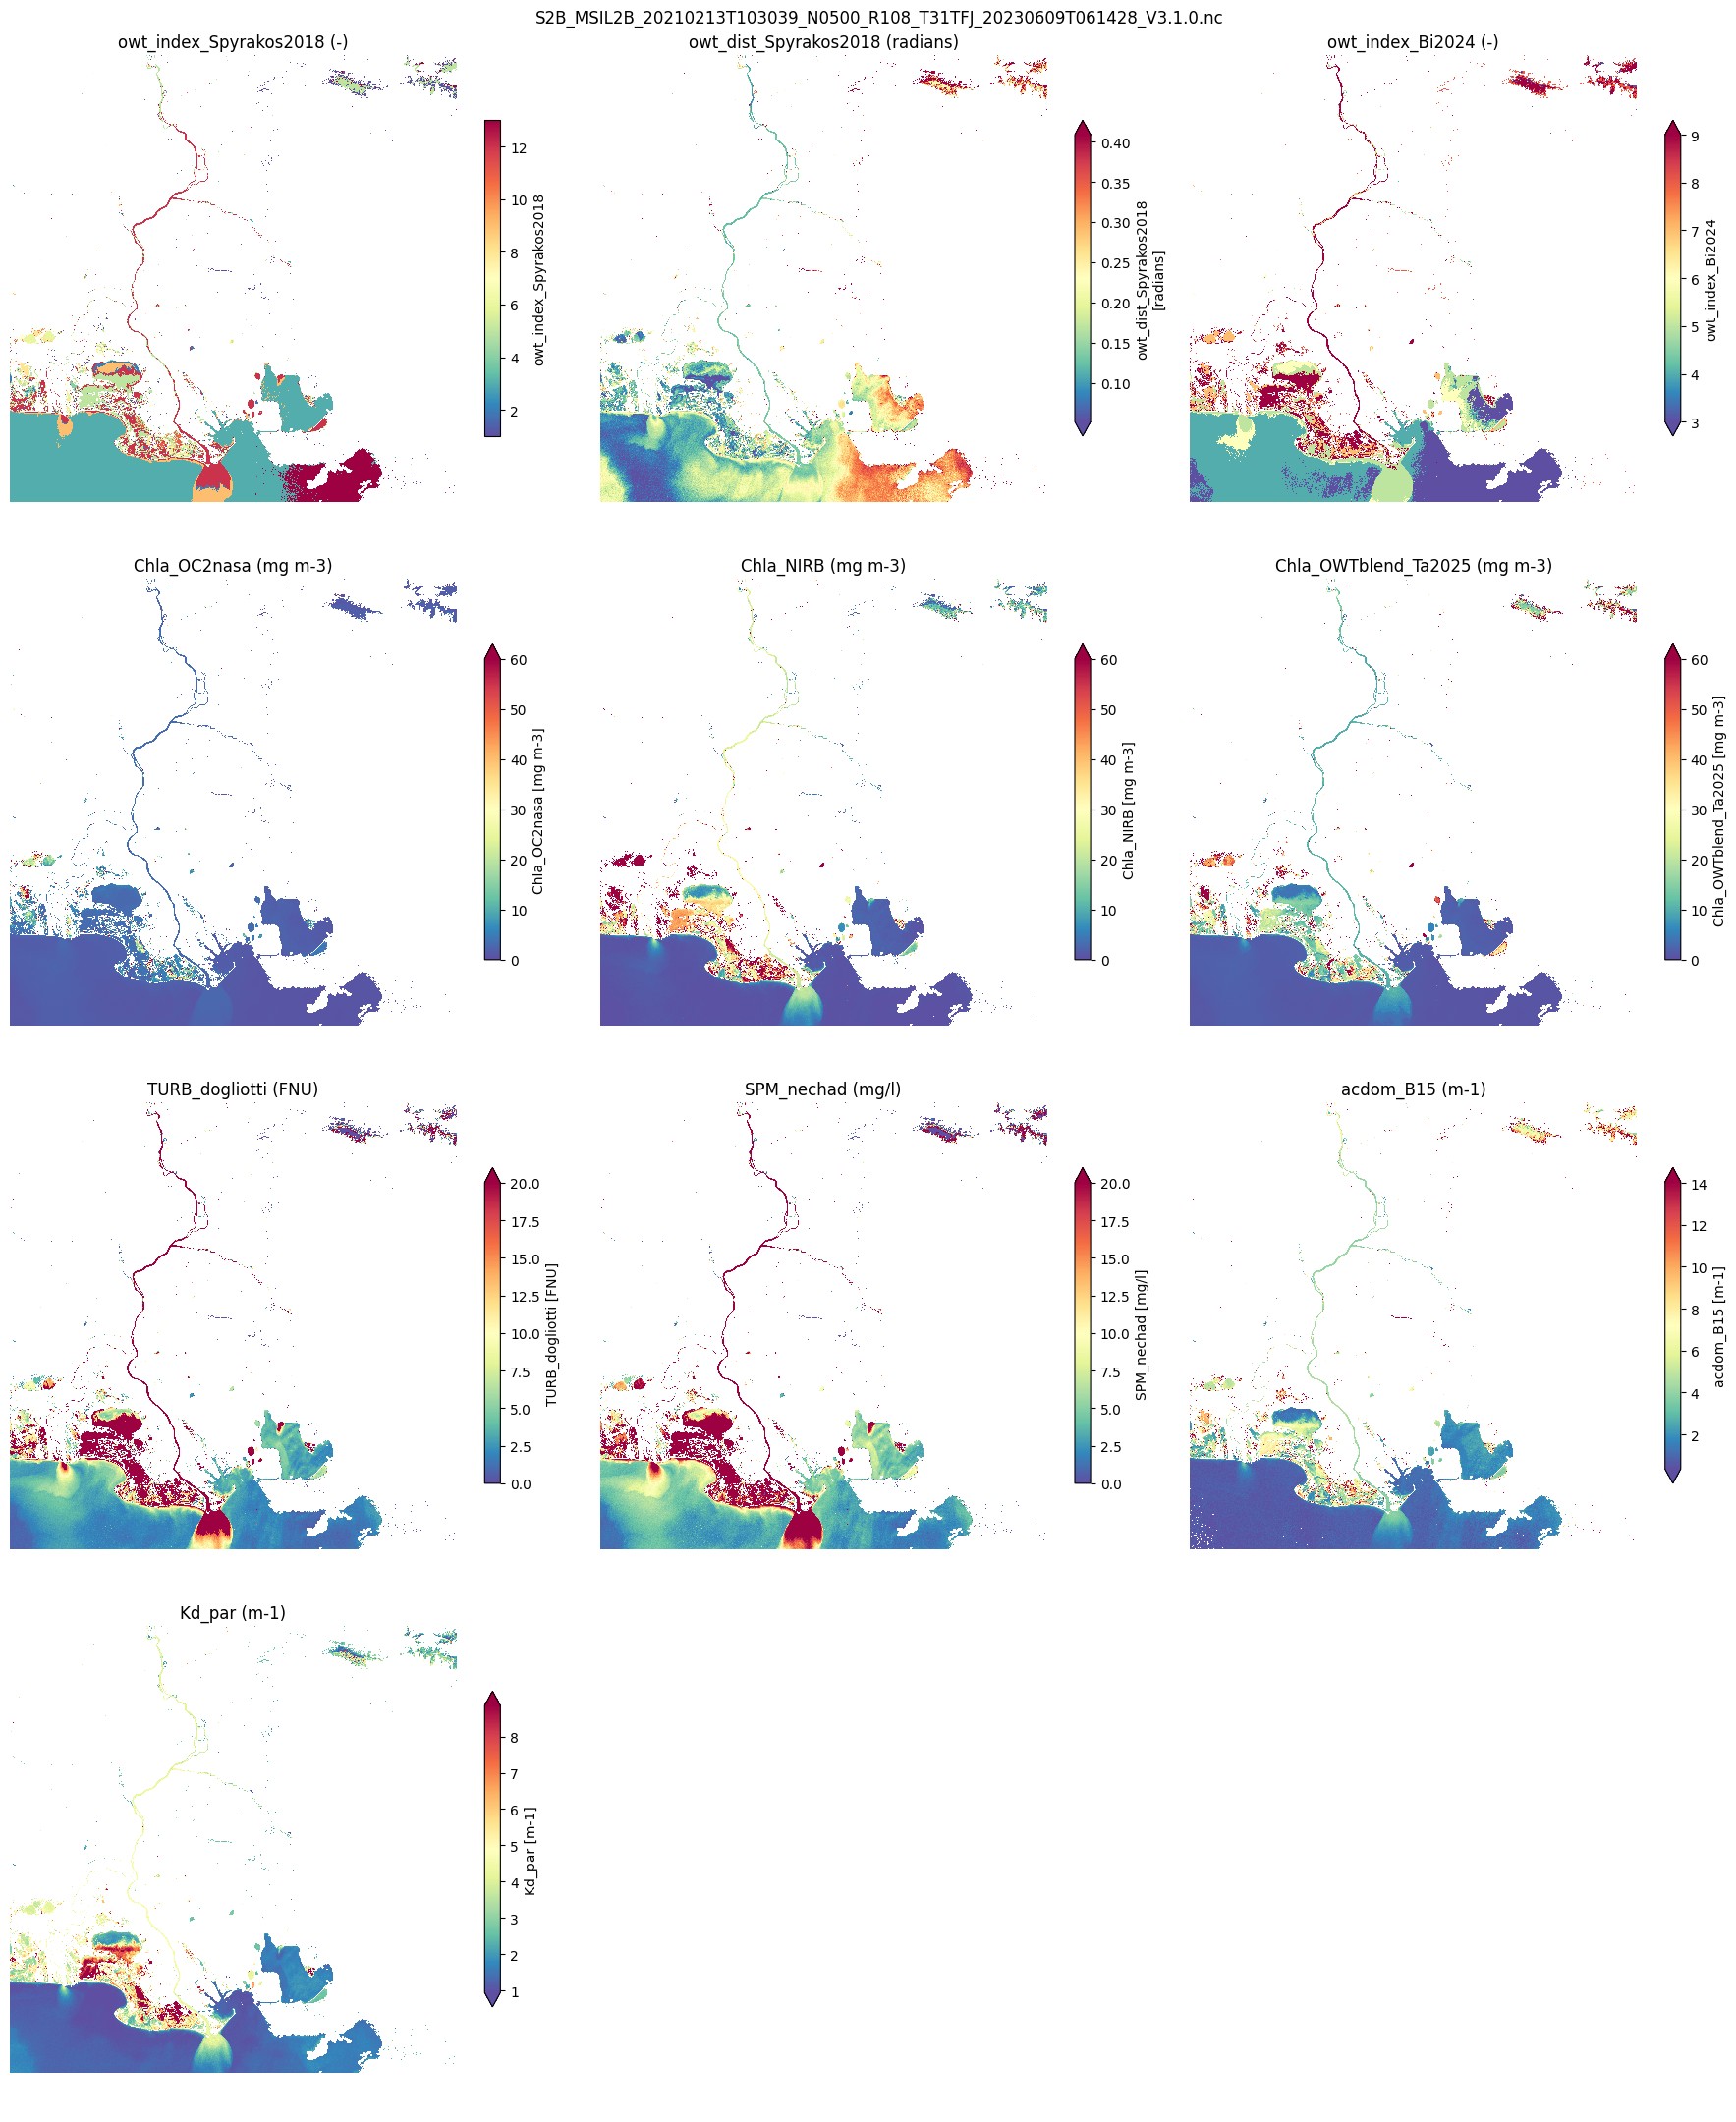

In [9]:
params = ['owt_index_Spyrakos2018', 'owt_dist_Spyrakos2018', 'owt_index_Bi2024',
          'Chla_OC2nasa', 'Chla_NIRB', 'Chla_OWTblend_Ta2025',
          'TURB_dogliotti', 'SPM_nechad', 'acdom_B15', 'Kd_par']
params = [p for p in params if p in l2b]
vmax = {'Chl': 60, 'TURB': 20, 'SPM': 20}   # colour scale upper limits by parameter family

# UTM projection from the EPSG code (326zz: north, 327zz: south)
epsg = l2b.rio.crs.to_epsg()
proj = ccrs.UTM(epsg % 100, southern_hemisphere=(epsg // 100 == 327))

ncols = 3
nrows = int(np.ceil(len(params) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5.5 * nrows),
                        subplot_kw={'projection': proj})
for ax in axs.ravel():
    ax.set_axis_off()
for ax, param in zip(axs.ravel(), params):
    da = l2b[param]
    if 'Nclasses' in da.dims:          # 3 best Spyrakos classes: show the first one
        da = da.isel(Nclasses=0)
    family = next((k for k in vmax if param.startswith(k)), None)
    kwargs = dict(vmin=0, vmax=vmax[family]) if family else {}
    da.squeeze().plot.imshow(ax=ax, cmap=plt.cm.Spectral_r, robust=True,
                             cbar_kwargs={'shrink': 0.6}, **kwargs)
    ax.set_title(f"{param} ({da.attrs.get('units', '-')})")
fig.suptitle(os.path.basename(l2b_file))
plt.tight_layout()

## Alternative: batch from the command line

For long batches, run one `GRSl2bgen` process per product from a shell script:
memory is fully released after each product. A full tile takes about 70 s and
6 GB of RAM (default of 8 threads), i.e. about 2 hours for 100 products. Products
can be processed in parallel with `xargs -P`: two at a time take about 90 s each
(about 45 s per product overall) but need twice the memory, so keep the number of
parallel products well within the free RAM. `--product_dir --stac` gives the folder
layout of section 3, and products whose STAC Item exists are skipped. The date range
is selected on the `YYYY/MM/DD` folders. The same script processes the GRS NetCDF
products (`<product>/<product>.nc`): set `rootdir` to their tree, e.g.
`/data/satellite/Sentinel-2/L2A`, and `version` to their GRS version, e.g. `V2.2.1`.

```bash
rootdir=/data/satellite/Sentinel-2/L2A_zarr
odir=/data/satellite/Sentinel-2/L2B
start=2021-01-01 end=2025-12-31
version=V3.1.0

process_one() {
    rel=${1#$rootdir/}                               # <tile>/YYYY/MM/DD/<product>
    name=$(basename "$1")
    l2b=$(sed -E 's/L2A(GRS)?/L2B/I' <<< "$name")   # MSIL2AGRS or MSIL2A -> MSIL2B
    out="$odir/$(dirname "$rel")/$l2b.nc"           # written to $l2b/ by --product_dir
    [ -e "$odir/$(dirname "$rel")/$l2b/$l2b.json" ] && return   # STAC Item: done
    # Zarr pyramid or NetCDF files (main and ancillary)
    [ -f "$1/$name.zarr/0/mask/zarr.json" ] || [ -f "$1/$name.nc" -a -f "$1/${name}_anc.nc" ] ||
        { echo "INCOMPLETE $1" >> "$odir/failed.txt"; return; }
    GRSl2bgen "$1" -o "$out" --product_dir --stac || echo "FAILED $1" >> "$odir/failed.txt"
}
export -f process_one; export rootdir odir

# products of the date range and version, one at a time (-P 2: two in parallel)
find "$rootdir" -mindepth 5 -maxdepth 5 -type d -name "*L2A*_$version" | sort |
    awk -v s="$start" -v e="$end" -F/ '{d=$(NF-3)"-"$(NF-2)"-"$(NF-1)} d>=s && d<=e' |
    xargs -P 1 -I{} bash -c 'process_one {}'
```